In [4]:
# ===== 팀 프로젝트 시작 셀 =====
import os, sys
from google.colab import userdata

TOKEN = userdata.get('GITHUB_TOKEN')
NAME = "Sooyong"
REPO_URL = "github.com/DA15-Lab/team3-ping-analytics.git"
PROJECT_DIR = "/content/team3-ping-analytics"

if not os.path.exists(PROJECT_DIR):
    !git clone -q https://{TOKEN}@{REPO_URL}
    %cd {PROJECT_DIR}
else:
    %cd {PROJECT_DIR}
    !git pull -q

!git config user.email "{NAME}@example.com"
!git config user.name "{NAME}"

!pip install -q -r requirements.txt

sys.path.append("/content/team3-ping-analytics/src")
from preprocess import *

print(module_test())
print("✅ 준비 완료")

/content/team3-ping-analytics
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 56.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
✅ 모듈 설치 완료
✅ 준비 완료


In [5]:
# 구글 드라이브 연결

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
# 라이브러리 불러오기

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

# 전처리

## accounts_attendance 테이블

In [7]:
# 데이터 불러오기

accounts_attendance = pd.read_csv('/content/drive/MyDrive/코드잇 3팀 고급 프로젝트/00_원본 csv/accounts_attendance.csv')

### 구조 파악

In [8]:
accounts_attendance.shape

(349637, 3)

- 349,637 rows
- 3 columns

In [9]:
accounts_attendance.head()

,id,attendance_date_list,user_id
0,1,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1446852
1,2,"[""2023-05-27"", ""2023-05-29"", ""2023-05-30"", ""20...",1359398
2,3,"[""2023-05-27"", ""2023-05-29"", ""2023-05-30"", ""20...",1501542
3,4,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1507767
4,5,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1287453


In [10]:
accounts_attendance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349637 entries, 0 to 349636
Data columns (total 3 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   id                    349637 non-null  int64 
 1   attendance_date_list  349637 non-null  object
 2   user_id               349637 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 8.0+ MB


- id: 데이터 적재 순서
- attendance_date_list: 출석일 리스트
  - 리스트 형태로 되어있어 풀어서 봐야할 듯
  - 데이터형이 object임 -> 날짜형으로 변경하자
- user_id: 유저 고유의 식별자

In [11]:
accounts_attendance.isna().sum()

,0
id,0
attendance_date_list,0
user_id,0


In [12]:
accounts_attendance.duplicated().sum()

np.int64(0)

- 결측치, 중복값 없음

#### attendance_date_list

In [13]:
# 1. 필요한 컬럼만 복사

attendance_base = accounts_attendance[
    ["id", "user_id", "attendance_date_list"]
].copy()

attendance_base = attendance_base.rename(
    columns={"id": "attendance_record_id"}
)

print(attendance_base.shape)
display(attendance_base.head())

(349637, 3)


,attendance_record_id,user_id,attendance_date_list
0,1,1446852,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20..."
1,2,1359398,"[""2023-05-27"", ""2023-05-29"", ""2023-05-30"", ""20..."
2,3,1501542,"[""2023-05-27"", ""2023-05-29"", ""2023-05-30"", ""20..."
3,4,1507767,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20..."
4,5,1287453,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20..."


In [14]:
# 2-1. 문자열을 실제 리스트로 변환

def parse_attendance_date_list(value):
    # 이미 리스트인 경우
    if isinstance(value, list):
        return value, False

    # 결측 또는 빈 문자열
    if pd.isna(value) or str(value).strip() == "":
        return [], False

    try:
        parsed = json.loads(value)

        # 리스트가 아닌 값이 들어온 경우
        if not isinstance(parsed, list):
            return [], True

        return parsed, False

    except (json.JSONDecodeError, TypeError):
        return [], True


parsed_result = attendance_base[
    "attendance_date_list"
].apply(parse_attendance_date_list)

attendance_base["attendance_dates"] = parsed_result.str[0]
attendance_base["parse_error"] = parsed_result.str[1]

In [15]:
# 2-2. 파싱 상태 확인

parse_validation = pd.Series(
    {
        "원본 행 수": len(attendance_base),
        "고유 사용자 수": attendance_base["user_id"].nunique(),
        "파싱 오류 행 수": attendance_base["parse_error"].sum(),
        "빈 날짜 리스트 행 수": attendance_base[
            "attendance_dates"
        ].str.len().eq(0).sum(),
    },
    name="value",
)

display(parse_validation.to_frame())

,value
원본 행 수,349637
고유 사용자 수,349637
파싱 오류 행 수,0
빈 날짜 리스트 행 수,20945


In [16]:
# 3. 출석 날짜별로 행 펼치기

attendance_long = (
    attendance_base.loc[
        ~attendance_base["parse_error"],
        [
            "attendance_record_id",
            "user_id",
            "attendance_dates",
        ],
    ]
    .explode(
        "attendance_dates",
        ignore_index=True,
    )
    .rename(
        columns={
            "attendance_dates": "attendance_date"
        }
    )
)

display(attendance_long.head(10))

,attendance_record_id,user_id,attendance_date
0,1,1446852,2023-05-27
1,1,1446852,2023-05-28
2,1,1446852,2023-05-29
3,1,1446852,2023-05-30
4,1,1446852,2023-06-03
5,1,1446852,2023-06-06
6,1,1446852,2023-06-12
7,1,1446852,2023-06-15
8,1,1446852,2023-07-10
9,1,1446852,2023-07-31


In [17]:
# 4. 빈 리스트 행 제거 및 날짜형 변환

attendance_long = attendance_long.dropna(
    subset=["attendance_date"]
).copy()

attendance_long["attendance_date"] = pd.to_datetime(
    attendance_long["attendance_date"],
    format="%Y-%m-%d",
    errors="coerce",
)

In [18]:
# 5. 중복 검사

duplicate_user_date_count = (
    attendance_long.duplicated(
        subset=["user_id", "attendance_date"]
    ).sum()
)

print(
    "중복 사용자-출석일 수:",
    f"{duplicate_user_date_count:,}",
)

중복 사용자-출석일 수: 0


In [19]:
# 6. 검증

attendance_validation = pd.Series(
    {
        "원본 사용자 행 수": len(attendance_base),
        "날짜가 있는 사용자 수": (
            attendance_long["user_id"].nunique()
        ),
        "사용자-출석일 행 수": len(attendance_long),
        "사용자-출석일 중복 수": (
            attendance_long.duplicated(
                ["user_id", "attendance_date"]
            ).sum()
        ),
        "최초 출석일": (
            attendance_long["attendance_date"].min()
        ),
        "마지막 출석일": (
            attendance_long["attendance_date"].max()
        ),
    },
    name="value",
)

display(attendance_validation.to_frame())
display(attendance_long.head(10))

,value
원본 사용자 행 수,349637
날짜가 있는 사용자 수,328692
사용자-출석일 행 수,2222327
사용자-출석일 중복 수,0
최초 출석일,2023-05-27 00:00:00
마지막 출석일,2024-05-09 00:00:00


,attendance_record_id,user_id,attendance_date
0,1,1446852,2023-05-27
1,1,1446852,2023-05-28
2,1,1446852,2023-05-29
3,1,1446852,2023-05-30
4,1,1446852,2023-06-03
5,1,1446852,2023-06-06
6,1,1446852,2023-06-12
7,1,1446852,2023-06-15
8,1,1446852,2023-07-10
9,1,1446852,2023-07-31


In [20]:
attendance_preprocessing_check = pd.Series(
    {
        # 원본 테이블 키 검증
        "attendance_record_id 결측": (
            attendance_base["attendance_record_id"].isna().sum()
        ),
        "attendance_record_id 중복": (
            attendance_base["attendance_record_id"].duplicated().sum()
        ),
        "user_id 결측": (
            attendance_base["user_id"].isna().sum()
        ),
        "user_id 중복": (
            attendance_base["user_id"].duplicated().sum()
        ),

        # 리스트 및 날짜 변환 검증
        "날짜 리스트 파싱 오류": (
            attendance_base["parse_error"].sum()
        ),
        "빈 날짜 리스트 사용자": (
            attendance_base["attendance_dates"].str.len().eq(0).sum()
        ),
        "날짜 변환 실패": (
            attendance_long["attendance_date"].isna().sum()
        ),

        # 행 수 보존 검증
        "리스트 내부 날짜 총개수": (
            attendance_base["attendance_dates"].str.len().sum()
        ),
        "펼친 후 사용자-날짜 행수": len(attendance_long),

        # 논리 중복 검증
        "사용자-날짜 중복": (
            attendance_long.duplicated(
                ["user_id", "attendance_date"]
            ).sum()
        ),
    },
    name="value",
)

display(attendance_preprocessing_check.to_frame())

,value
attendance_record_id 결측,0
attendance_record_id 중복,0
user_id 결측,0
user_id 중복,0
날짜 리스트 파싱 오류,0
빈 날짜 리스트 사용자,20945
날짜 변환 실패,0
리스트 내부 날짜 총개수,2222327
펼친 후 사용자-날짜 행수,2222327
사용자-날짜 중복,0


#### user_id

In [21]:
accounts_attendance['user_id'].nunique()

349637

## accounts_blockrecord 테이블

### 구조 파악

In [22]:
accounts_blockrecord = pd.read_csv('/content/drive/MyDrive/코드잇 3팀 고급 프로젝트/00_원본 csv/accounts_blockrecord.csv')

In [23]:
accounts_blockrecord.shape

(19482, 5)

- 19,482 rows
- 5 columns

In [24]:
accounts_blockrecord.head()

,id,reason,created_at,block_user_id,user_id
0,1,그냥...,2023-05-04 23:01:53,867483,878476
1,2,친구 사이가 어색해짐,2023-05-05 01:17:08,867190,867564
2,3,나랑 관련 없는 질문을 자꾸 보냄,2023-05-05 01:50:55,875110,875261
3,6,그냥...,2023-05-05 05:21:52,883696,883511
4,7,그냥...,2023-05-05 06:40:34,871349,870177


In [25]:
accounts_blockrecord.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19482 entries, 0 to 19481
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   id             19482 non-null  int64 
 1   reason         19482 non-null  object
 2   created_at     19482 non-null  object
 3   block_user_id  19482 non-null  int64 
 4   user_id        19482 non-null  int64 
dtypes: int64(3), object(2)
memory usage: 761.1+ KB


- id: 데이터 적재 순서
- reason: 차단 이유
- created_at: 차단 시점
  - 날짜형으로 변경해야 함
- block_user_id: 차단된 유저
- user_id: 차단한 유저

In [26]:
accounts_blockrecord.isna().sum()

,0
id,0
reason,0
created_at,0
block_user_id,0
user_id,0


In [27]:
accounts_blockrecord.duplicated().sum()

np.int64(0)

- 결측치, 중복값 없음

In [28]:
accounts_blockrecord.describe()

,id,block_user_id,user_id
count,19482.000000,1.948200e+04,1.948200e+04
mean,12694.563495,1.183576e+06,1.175780e+06
std,7220.338199,2.049517e+05,2.043189e+05
min,1.000000,8.327400e+05,8.376150e+05
25%,6514.250000,1.001336e+06,9.890410e+05
50%,12731.000000,1.173390e+06,1.160726e+06
75%,18984.750000,1.357468e+06,1.345758e+06
max,25361.000000,1.582869e+06,1.583612e+06


#### reason

In [29]:
accounts_blockrecord['reason'].value_counts(normalize=True)

,proportion
reason,
모르는 사람임,0.494816
친구 사이가 어색해짐,0.297967
사칭 계정,0.103788
나랑 관련 없는 질문을 자꾸 보냄,0.055590
너무 많은 양의 질문을 보냄,0.047172
기타,0.000359
그냥...,0.000308


#### created_at

In [30]:
# 날짜형으로 변경

accounts_blockrecord["created_at"] = pd.to_datetime(
    accounts_blockrecord["created_at"]
)

In [31]:
accounts_blockrecord["created_at"].dtype

dtype('<M8[ns]')

In [32]:
accounts_blockrecord['created_at'].min()

Timestamp('2023-05-04 23:01:53')

In [33]:
accounts_blockrecord['created_at'].max()

Timestamp('2024-05-06 13:03:37')

In [34]:
# 시간 파생변수 만들기

sns.set_theme(style="whitegrid")

block = accounts_blockrecord.copy()

block["created_at"] = (
    pd.to_datetime(
        block["created_at"]
    )
)

# 변환 실패 행 제외
block = block.dropna(
    subset=["created_at"]
).copy()

# 시간대 분석이 편하도록 timezone 제거
block["local_datetime"] = (
    block["created_at"]
    .dt.tz_localize(None)
)

weekday_order = [
    "월", "화", "수", "목", "금", "토", "일"
]

block["date"] = (
    block["local_datetime"].dt.normalize()
)

block["hour"] = (
    block["local_datetime"].dt.hour
)

block["weekday_num"] = (
    block["local_datetime"].dt.dayofweek
)

block["weekday"] = (
    block["weekday_num"]
    .map(dict(enumerate(weekday_order)))
)

block["week_start"] = (
    block["local_datetime"]
    .dt.to_period("W-SUN")
    .dt.start_time
)

block["month"] = (
    block["local_datetime"]
    .dt.to_period("M")
    .astype(str)
)

print(f"전체 차단 기록: {len(block):,}건")
print("최초 차단:", block["created_at"].min())
print("마지막 차단:", block["created_at"].max())

전체 차단 기록: 19,482건
최초 차단: 2023-05-04 23:01:53
마지막 차단: 2024-05-06 13:03:37


In [35]:
# 일/주/월별 집계

full_date_range = pd.date_range(
    start=block["date"].min(),
    end=block["date"].max(),
    freq="D",
)

daily_summary = (
    block.groupby("date")
    .size()
    .reindex(full_date_range, fill_value=0)
    .rename("block_count")
    .to_frame()
)

daily_summary.index.name = "date"

# 일별 변동을 부드럽게 보기 위한 7일 이동평균
daily_summary["rolling_7d_mean"] = (
    daily_summary["block_count"]
    .rolling(7, min_periods=1)
    .mean()
)

weekly_summary = (
    daily_summary["block_count"]
    .resample("W-SUN")
    .sum()
    .rename("block_count")
    .to_frame()
)

monthly_summary = (
    daily_summary
    .assign(
        month=daily_summary.index.to_period("M")
    )
    .groupby("month")
    .agg(
        total_blocks=("block_count", "sum"),
        daily_mean=("block_count", "mean"),
        daily_median=("block_count", "median"),
        observed_days=("block_count", "size"),
    )
)

monthly_summary.index = (
    monthly_summary.index.astype(str)
)

display(monthly_summary.round(2))

,total_blocks,daily_mean,daily_median,observed_days
month,,,,
2023-05,16442,587.21,593.5,28
2023-06,2262,75.40,49.0,30
2023-07,410,13.23,12.0,31
2023-08,159,5.13,3.0,31
2023-09,103,3.43,1.5,30
2023-10,11,0.35,0.0,31
2023-11,16,0.53,0.0,30
2023-12,9,0.29,0.0,31
2024-01,9,0.29,0.0,31


In [36]:
# 시간대별 집계

hour_summary = (
    block.groupby("hour")
    .size()
    .reindex(range(24), fill_value=0)
    .rename("block_count")
    .to_frame()
)

hour_summary["rate_pct"] = (
    hour_summary["block_count"]
    / hour_summary["block_count"].sum()
    * 100
)

display(hour_summary.round(2))

,block_count,rate_pct
hour,,
0,366,1.88
1,585,3.00
2,556,2.85
3,562,2.88
4,579,2.97
5,634,3.25
6,829,4.26
7,1140,5.85
8,1047,5.37


In [37]:
# 요일별 집계

weekday_daily = daily_summary.copy()

weekday_daily["weekday_num"] = (
    weekday_daily.index.dayofweek
)

weekday_summary = (
    weekday_daily
    .groupby("weekday_num")
    .agg(
        total_blocks=("block_count", "sum"),
        daily_mean=("block_count", "mean"),
        daily_median=("block_count", "median"),
        observed_days=("block_count", "size"),
    )
    .reindex(range(7))
)

weekday_summary["weekday"] = weekday_order

weekday_summary = (
    weekday_summary
    .set_index("weekday")
)

display(weekday_summary.round(2))

,total_blocks,daily_mean,daily_median,observed_days
weekday,,,,
월,2766,52.19,0.0,53
화,2350,45.19,0.5,52
수,2647,50.90,0.5,52
목,2663,50.25,1.0,53
금,2483,46.85,0.0,53
토,3287,62.02,1.0,53
일,3286,62.00,1.0,53


In [38]:
# 요일, 시간대별 히트맵

date_hour_index = pd.MultiIndex.from_product(
    [
        full_date_range,
        range(24),
    ],
    names=["date", "hour"],
)

date_hour_summary = (
    block.groupby(["date", "hour"])
    .size()
    .reindex(date_hour_index, fill_value=0)
    .rename("block_count")
    .reset_index()
)

date_hour_summary["weekday_num"] = (
    date_hour_summary["date"].dt.dayofweek
)

weekday_hour_heatmap = (
    date_hour_summary
    .pivot_table(
        index="weekday_num",
        columns="hour",
        values="block_count",
        aggfunc="mean",
        fill_value=0,
    )
    .reindex(index=range(7), columns=range(24))
)

weekday_hour_heatmap.index = weekday_order

In [39]:
!pip install koreanize_matplotlib

import koreanize_matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 96.9 MB/s eta 0:00:00


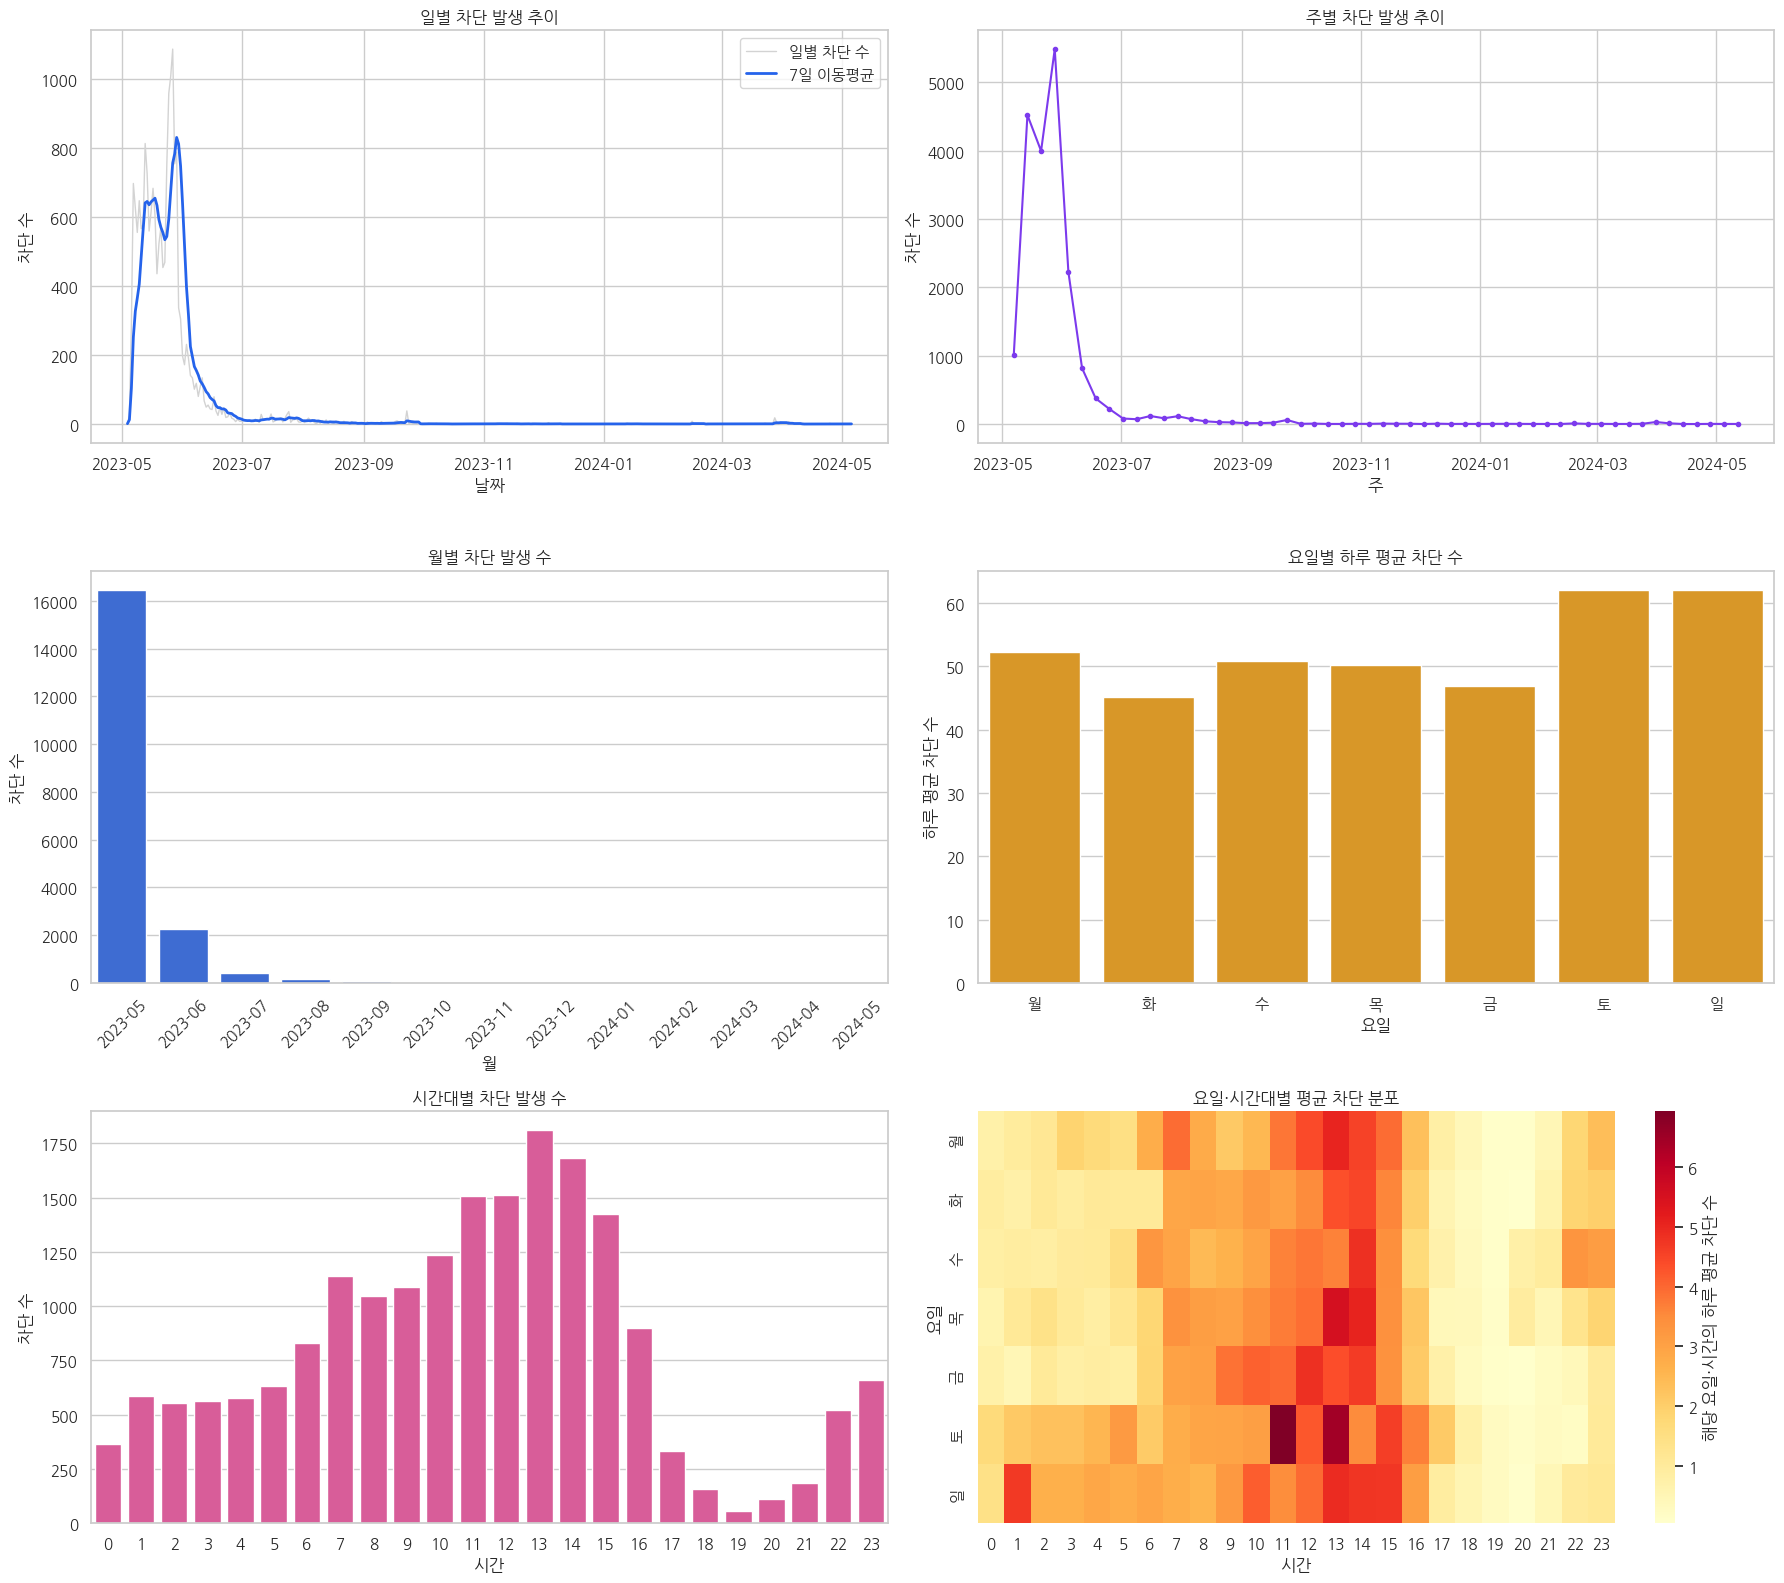

In [40]:
# 차트화

fig, axes = plt.subplots(
    3,
    2,
    figsize=(18, 16),
)

# ① 일별 차단 발생 추이
axes[0, 0].plot(
    daily_summary.index,
    daily_summary["block_count"],
    color="lightgray",
    linewidth=1,
    label="일별 차단 수",
)

axes[0, 0].plot(
    daily_summary.index,
    daily_summary["rolling_7d_mean"],
    color="#2563EB",
    linewidth=2,
    label="7일 이동평균",
)

axes[0, 0].set_title("일별 차단 발생 추이")
axes[0, 0].set_xlabel("날짜")
axes[0, 0].set_ylabel("차단 수")
axes[0, 0].legend()


# ② 주별 차단 발생 추이
axes[0, 1].plot(
    weekly_summary.index,
    weekly_summary["block_count"],
    color="#7C3AED",
    marker="o",
    markersize=3,
)

axes[0, 1].set_title("주별 차단 발생 추이")
axes[0, 1].set_xlabel("주")
axes[0, 1].set_ylabel("차단 수")


# ③ 월별 차단 발생 수
sns.barplot(
    x=monthly_summary.index,
    y=monthly_summary["total_blocks"],
    color="#2563EB",
    ax=axes[1, 0],
)

axes[1, 0].set_title("월별 차단 발생 수")
axes[1, 0].set_xlabel("월")
axes[1, 0].set_ylabel("차단 수")
axes[1, 0].tick_params(
    axis="x",
    rotation=45,
)


# ④ 요일별 하루 평균 차단 수
sns.barplot(
    x=weekday_summary.index,
    y=weekday_summary["daily_mean"],
    color="#F59E0B",
    ax=axes[1, 1],
)

axes[1, 1].set_title("요일별 하루 평균 차단 수")
axes[1, 1].set_xlabel("요일")
axes[1, 1].set_ylabel("하루 평균 차단 수")


# ⑤ 시간대별 차단 분포
sns.barplot(
    x=hour_summary.index,
    y=hour_summary["block_count"],
    color="#EC4899",
    ax=axes[2, 0],
)

axes[2, 0].set_title("시간대별 차단 발생 수")
axes[2, 0].set_xlabel("시간")
axes[2, 0].set_ylabel("차단 수")


# ⑥ 요일 × 시간대 히트맵
sns.heatmap(
    weekday_hour_heatmap,
    cmap="YlOrRd",
    ax=axes[2, 1],
    cbar_kws={
        "label": "해당 요일·시간의 하루 평균 차단 수"
    },
)

axes[2, 1].set_title("요일·시간대별 평균 차단 분포")
axes[2, 1].set_xlabel("시간")
axes[2, 1].set_ylabel("요일")

plt.tight_layout()
plt.show()

#### user_id

In [41]:
accounts_blockrecord['user_id'].nunique()

12552

In [42]:
# user_id별 전체 행 수
block_count_by_user = (
    accounts_blockrecord
    .groupby("user_id")
    .size()
    .rename("block_count")
    .reset_index()
)

display(block_count_by_user.head())

,user_id,block_count
0,837615,1
1,837786,2
2,838168,5
3,839217,1
4,839558,1


In [43]:
top10_block_users = (
    accounts_blockrecord
    .groupby("user_id")
    .size()
    .rename("block_count")
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

display(top10_block_users)

,user_id,block_count
0,1526194,171
1,1415197,163
2,1519819,70
3,1542675,66
4,986459,60
5,1536035,39
6,879416,38
7,1296499,34
8,1343300,34
9,1155373,33


In [44]:
one_block_user_count = (
    block_count_by_user["block_count"]
    .eq(1)
    .sum()
)

In [45]:
block_user_summary = pd.Series(
    {
        "전체 차단 기록 수": len(accounts_blockrecord),
        "차단한 고유 사용자 수": (
            accounts_blockrecord["user_id"].nunique()
        ),
        "차단 기록이 1건인 사용자 수": (
            one_block_user_count
        ),
        "차단 기록이 2건 이상인 사용자 수": (
            block_count_by_user["block_count"]
            .ge(2)
            .sum()
        ),
    },
    name="value",
)

display(block_user_summary.to_frame())

,value
전체 차단 기록 수,19482
차단한 고유 사용자 수,12552
차단 기록이 1건인 사용자 수,9819
차단 기록이 2건 이상인 사용자 수,2733


#### block_user_id

In [46]:
accounts_blockrecord['block_user_id'].nunique()

16240

In [47]:
# block_user_id별 전체 행 수
blocked_count_by_user = (
    accounts_blockrecord
    .groupby("block_user_id")
    .size()
    .rename("blocked_count")
    .reset_index()
)

display(blocked_count_by_user.head())

,block_user_id,blocked_count
0,832740,1
1,833422,1
2,834486,1
3,835888,1
4,835907,1


In [48]:
top10_blocked_users = (
    accounts_blockrecord
    .groupby("block_user_id")
    .size()
    .rename("blocked_count")
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

display(top10_blocked_users)

,block_user_id,blocked_count
0,898020,76
1,877266,25
2,897681,25
3,1380465,25
4,1395312,24
5,876207,24
6,1198628,21
7,1495281,19
8,1031842,18
9,1186363,17


In [49]:
one_blocked_user_count = (
    blocked_count_by_user["blocked_count"]
    .eq(1)
    .sum()
)

In [50]:
blocked_user_summary = pd.Series(
    {
        "전체 차단 기록 수": len(accounts_blockrecord),
        "차단 당한 고유 사용자 수": (
            accounts_blockrecord["block_user_id"].nunique()
        ),
        "차단 당한 기록이 1건인 사용자 수": (
            one_blocked_user_count
        ),
        "차단 당한 기록이 2건 이상인 사용자 수": (
            blocked_count_by_user["blocked_count"]
            .ge(2)
            .sum()
        ),
    },
    name="value",
)

display(blocked_user_summary.to_frame())

,value
전체 차단 기록 수,19482
차단 당한 고유 사용자 수,16240
차단 당한 기록이 1건인 사용자 수,14556
차단 당한 기록이 2건 이상인 사용자 수,1684


### 이상치 판단

In [51]:
# 자기 자신 차단
accounts_blockrecord[accounts_blockrecord['user_id'].eq(accounts_blockrecord["block_user_id"])]

,id,reason,created_at,block_user_id,user_id
4703,6311,모르는 사람임,2023-05-13 16:18:21,877237,877237
4728,6339,사칭 계정,2023-05-13 16:42:05,1012792,1012792
4736,6347,모르는 사람임,2023-05-13 16:50:57,1095213,1095213
4852,6496,친구 사이가 어색해짐,2023-05-14 01:45:40,1197100,1197100
6293,8373,모르는 사람임,2023-05-16 09:12:16,1315402,1315402
6966,9208,모르는 사람임,2023-05-17 10:04:46,1347875,1347875
8231,10777,모르는 사람임,2023-05-19 12:23:58,1374659,1374659
8237,10784,너무 많은 양의 질문을 보냄,2023-05-19 12:39:31,1365534,1365534
8688,11356,친구 사이가 어색해짐,2023-05-20 11:26:13,1358480,1358480
8741,11423,나랑 관련 없는 질문을 자꾸 보냄,2023-05-20 12:54:32,1141855,1141855


- 자기 자신을 차단한 사례 -> 전부 삭제 처리 진행

In [52]:
accounts_blockrecord[accounts_blockrecord.duplicated(
    subset=[
        "user_id",
        "block_user_id",
        "created_at",
    ],
    keep=False,
)]

,id,reason,created_at,block_user_id,user_id
900,1224,너무 많은 양의 질문을 보냄,2023-05-07 15:21:55,954305,917978
901,1225,모르는 사람임,2023-05-07 15:21:55,954305,917978
1125,1509,모르는 사람임,2023-05-08 06:31:49,977940,967723
1126,1510,모르는 사람임,2023-05-08 06:31:49,977940,967723
1882,2555,모르는 사람임,2023-05-09 11:55:42,1025677,971524
1883,2556,모르는 사람임,2023-05-09 11:55:42,1025677,971524
1884,2557,모르는 사람임,2023-05-09 11:55:43,1025677,971524
1885,2558,모르는 사람임,2023-05-09 11:55:43,1025677,971524
1886,2559,모르는 사람임,2023-05-09 11:55:43,1025677,971524
2878,3876,나랑 관련 없는 질문을 자꾸 보냄,2023-05-11 05:13:32,977215,1117631


- 동일인이 동일인을 같은 시간에 차단한 사례
  - reason이 같은 경우와 다른 경우 혼재
    - 같은 경우: 한 행만 남기고 삭제 처리
    - 다른 경우: id의 수치가 가장 작은 행만 남기고 삭제 처리

In [53]:
accounts_blockrecord[accounts_blockrecord.duplicated(
    subset=[
        "user_id",
        "block_user_id",
    ],
    keep=False,
)].sort_values('created_at')

,id,reason,created_at,block_user_id,user_id
8,12,기타,2023-05-05 13:04:31,885794,879662
9,13,기타,2023-05-05 13:04:42,885794,879662
10,14,그냥...,2023-05-05 13:04:52,885794,879662
11,15,기타,2023-05-05 13:04:56,885794,879662
12,16,기타,2023-05-05 13:05:01,885794,879662
...,...,...,...,...,...
19228,24886,모르는 사람임,2023-08-15 18:38:41,992181,1072478
19240,24899,친구 사이가 어색해짐,2023-08-18 12:12:28,1500131,1365572
19248,24912,모르는 사람임,2023-08-21 23:12:23,1029653,955098
19295,25105,모르는 사람임,2023-09-11 14:09:18,1019326,976341


- 동일인이 동일인을 차단한 사례
  - 조심해야할 점: 시각이 다르므로, 차단했다가 푼 다음 다시 차단한 경우도 가능하므로 전부 이상치로 처리하면 안됨

### 이상치 처리

In [54]:
# 원본 테이블 보호
block_raw = accounts_blockrecord.copy()

# 차단 사유 문자열 정리
block_raw["reason"] = (
    block_raw["reason"]
    .astype("string")
    .str.strip()
)

# id가 작은 행부터 정렬
block_raw = block_raw.sort_values("id").copy()

#### 자기 자신 차단

In [55]:
# 자기 자신을 차단한 행

self_block_mask = (
    block_raw["user_id"]
    .eq(block_raw["block_user_id"])
)

self_block_rows = (
    block_raw.loc[self_block_mask]
    .copy()
)

print("자기 자신 차단 행:", f"{len(self_block_rows):,}")

display(self_block_rows)

자기 자신 차단 행: 33


,id,reason,created_at,block_user_id,user_id
4703,6311,모르는 사람임,2023-05-13 16:18:21,877237,877237
4728,6339,사칭 계정,2023-05-13 16:42:05,1012792,1012792
4736,6347,모르는 사람임,2023-05-13 16:50:57,1095213,1095213
4852,6496,친구 사이가 어색해짐,2023-05-14 01:45:40,1197100,1197100
6293,8373,모르는 사람임,2023-05-16 09:12:16,1315402,1315402
6966,9208,모르는 사람임,2023-05-17 10:04:46,1347875,1347875
8231,10777,모르는 사람임,2023-05-19 12:23:58,1374659,1374659
8237,10784,너무 많은 양의 질문을 보냄,2023-05-19 12:39:31,1365534,1365534
8688,11356,친구 사이가 어색해짐,2023-05-20 11:26:13,1358480,1358480
8741,11423,나랑 관련 없는 질문을 자꾸 보냄,2023-05-20 12:54:32,1141855,1141855


In [56]:
block_valid = (
    block_raw.loc[
        ~self_block_mask
        & block_raw["created_at"].notna()
    ]
    .copy()
)

#### 동일인이 동일인을 같은 시각에 차단한 경우

In [57]:
# reason이 같은 경우

reason_record_keys = [
    "user_id",
    "block_user_id",
    "created_at",
    "reason",
]

exact_duplicate_mask = (
    block_valid.duplicated(
        subset=reason_record_keys,
        keep=False,
    )
)

exact_duplicate_rows = (
    block_valid.loc[exact_duplicate_mask]
    .sort_values(reason_record_keys + ["id"])
)

print(
    "완전 동일 중복에 관여한 전체 행:",
    f"{len(exact_duplicate_rows):,}",
)

display(exact_duplicate_rows)

완전 동일 중복에 관여한 전체 행: 9


,id,reason,created_at,block_user_id,user_id
4615,6161,모르는 사람임,2023-05-13 14:54:47,931725,859334
4616,6162,모르는 사람임,2023-05-13 14:54:47,931725,859334
1125,1509,모르는 사람임,2023-05-08 06:31:49,977940,967723
1126,1510,모르는 사람임,2023-05-08 06:31:49,977940,967723
1882,2555,모르는 사람임,2023-05-09 11:55:42,1025677,971524
1883,2556,모르는 사람임,2023-05-09 11:55:42,1025677,971524
1884,2557,모르는 사람임,2023-05-09 11:55:43,1025677,971524
1885,2558,모르는 사람임,2023-05-09 11:55:43,1025677,971524
1886,2559,모르는 사람임,2023-05-09 11:55:43,1025677,971524


In [58]:
# id가 작은 값 한행만 남기고 삭제
block_reason_clean = (
    block_valid
    .sort_values("id")
    .drop_duplicates(
        subset=reason_record_keys,
        keep="first",
    )
    .copy()
)

exact_duplicate_removed = (
    len(block_valid)
    - len(block_reason_clean)
)

print(
    "완전 동일 중복으로 제거된 행:",
    f"{exact_duplicate_removed:,}",
)

완전 동일 중복으로 제거된 행: 5


In [59]:
# reason이 다른 경우

event_keys = [
    "user_id",
    "block_user_id",
    "created_at",
]

same_event_summary = (
    block_reason_clean
    .groupby(
        event_keys,
        as_index=False,
        dropna=False,
    )
    .agg(
        rows=("id", "size"),
        reason_count=("reason", "nunique"),
        reason_list=(
            "reason",
            lambda x: tuple(pd.unique(x.dropna())),
        ),
        min_id=("id", "min"),
    )
)

reason_conflict_events = (
    same_event_summary.loc[
        same_event_summary["reason_count"] > 1
    ]
    .copy()
)

print(
    "동일 시각에 사유가 여러 개인 차단 사건:",
    f"{len(reason_conflict_events):,}",
)

display(reason_conflict_events)

동일 시각에 사유가 여러 개인 차단 사건: 8


,user_id,block_user_id,created_at,rows,reason_count,reason_list,min_id
956,889161,876197,2023-05-16 11:27:34,3,3,"(너무 많은 양의 질문을 보냄, 모르는 사람임, 나랑 관련 없는 질문을 자꾸 보냄)",8492
957,889161,876197,2023-05-16 11:27:35,3,3,"(너무 많은 양의 질문을 보냄, 모르는 사람임, 나랑 관련 없는 질문을 자꾸 보냄)",8495
2077,917978,954305,2023-05-07 15:21:55,2,2,"(너무 많은 양의 질문을 보냄, 모르는 사람임)",1224
8460,1117631,977215,2023-05-11 05:13:32,2,2,"(나랑 관련 없는 질문을 자꾸 보냄, 친구 사이가 어색해짐)",3876
9968,1169540,1171686,2023-05-13 02:32:43,2,2,"(모르는 사람임, 나랑 관련 없는 질문을 자꾸 보냄)",5426
10184,1176971,1161603,2023-05-18 14:21:02,2,2,"(나랑 관련 없는 질문을 자꾸 보냄, 너무 많은 양의 질문을 보냄)",10181
10713,1196057,923491,2023-05-17 23:45:17,2,2,"(친구 사이가 어색해짐, 너무 많은 양의 질문을 보냄)",9726
11404,1221770,1223805,2023-05-15 04:44:17,2,2,"(너무 많은 양의 질문을 보냄, 모르는 사람임)",7413


In [60]:
block_event_clean = (
    block_reason_clean
    .sort_values("id")
    .groupby(
        event_keys,
        as_index=False,
        dropna=False,
    )
    .agg(
        # 해당 사건에서 가장 작은 id
        id=("id", "min"),

        # 가장 작은 id 행의 대표 사유
        reason=("reason", "first"),

        # 실제로 기록된 모든 사유
        reason_list=(
            "reason",
            lambda x: tuple(pd.unique(x.dropna())),
        ),

        # 서로 다른 사유 개수
        reason_count=("reason", "nunique"),
    )
)

block_event_clean["has_reason_conflict"] = (
    block_event_clean["reason_count"] > 1
)

reason_conflict_collapsed = (
    len(block_reason_clean)
    - len(block_event_clean)
)

#### 동일인이 동일인을 다른 시각에 차단한 경우

In [61]:
pair_keys = [
    "user_id",
    "block_user_id",
]

block_event_clean = (
    block_event_clean
    .sort_values(
        pair_keys + ["created_at", "id"]
    )
    .reset_index(drop=True)
)

# 동일 관계 내 차단 기록 순서
block_event_clean["block_order_within_pair"] = (
    block_event_clean
    .groupby(pair_keys)
    .cumcount()
    .add(1)
)

# 동일 관계의 이전 차단 시각
block_event_clean["previous_block_at"] = (
    block_event_clean
    .groupby(pair_keys)["created_at"]
    .shift()
)

# 이전 차단 기록과의 간격
block_event_clean["seconds_since_previous_block"] = (
    block_event_clean["created_at"]
    - block_event_clean["previous_block_at"]
).dt.total_seconds()

# 동일 관계에서 두 번째 이상 등장한 기록
block_event_clean["is_repeated_pair"] = (
    block_event_clean["block_order_within_pair"] > 1
)

In [62]:
# 1분 이내 반복된 행 확인

block_event_clean["is_rapid_repeat_60s"] = (
    block_event_clean[
        "seconds_since_previous_block"
    ].between(
        0,
        60,
        inclusive="right",
    )
)

rapid_repeat_rows = (
    block_event_clean.loc[
        block_event_clean["is_rapid_repeat_60s"]
    ]
    .sort_values(
        pair_keys + ["created_at"]
    )
)

print(
    "60초 이내 반복된 차단 사건:",
    f"{len(rapid_repeat_rows):,}",
)

display(rapid_repeat_rows.head(100))

60초 이내 반복된 차단 사건: 486


,user_id,block_user_id,created_at,id,reason,reason_list,reason_count,has_reason_conflict,block_order_within_pair,previous_block_at,seconds_since_previous_block,is_repeated_pair,is_rapid_repeat_60s
118,847011,897681,2023-05-08 08:41:45,1617,너무 많은 양의 질문을 보냄,"(너무 많은 양의 질문을 보냄,)",1,False,2,2023-05-08 08:41:27,18.0,True,True
139,848687,920457,2023-05-07 05:25:31,599,모르는 사람임,"(모르는 사람임,)",1,False,2,2023-05-07 05:25:00,31.0,True,True
140,848687,920457,2023-05-07 05:25:34,600,모르는 사람임,"(모르는 사람임,)",1,False,3,2023-05-07 05:25:31,3.0,True,True
183,851333,852860,2023-05-06 08:35:18,107,친구 사이가 어색해짐,"(친구 사이가 어색해짐,)",1,False,2,2023-05-06 08:35:02,16.0,True,True
208,852455,847301,2023-05-07 08:51:18,760,친구 사이가 어색해짐,"(친구 사이가 어색해짐,)",1,False,3,2023-05-07 08:51:01,17.0,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1790,909818,898020,2023-05-07 09:13:17,780,너무 많은 양의 질문을 보냄,"(너무 많은 양의 질문을 보냄,)",1,False,6,2023-05-07 09:13:14,3.0,True,True
1793,909818,898020,2023-05-07 12:52:30,1003,나랑 관련 없는 질문을 자꾸 보냄,"(나랑 관련 없는 질문을 자꾸 보냄,)",1,False,9,2023-05-07 12:52:22,8.0,True,True
1796,909818,898020,2023-05-08 15:42:22,2043,나랑 관련 없는 질문을 자꾸 보냄,"(나랑 관련 없는 질문을 자꾸 보냄,)",1,False,12,2023-05-08 15:42:20,2.0,True,True
1797,909818,898020,2023-05-08 15:42:24,2044,나랑 관련 없는 질문을 자꾸 보냄,"(나랑 관련 없는 질문을 자꾸 보냄,)",1,False,13,2023-05-08 15:42:22,2.0,True,True


### 결과

In [63]:
block_preprocessing_summary = pd.Series(
    {
        "원본 행 수": len(block_raw),
        "제외된 자기 자신 차단 행": len(self_block_rows),
        "완전 동일 중복 제거 행": exact_duplicate_removed,
        "사유 단위 최종 행 수": len(block_reason_clean),
        "복수 사유 통합으로 감소한 행": (
            reason_conflict_collapsed
        ),
        "차단 사건 단위 최종 행 수": len(block_event_clean),
        "복수 사유 차단 사건 수": (
            block_event_clean["has_reason_conflict"].sum()
        ),
        "두 번째 이상 반복 차단 사건": (
            block_event_clean["is_repeated_pair"].sum()
        ),
        "60초 이내 반복 사건": (
            block_event_clean["is_rapid_repeat_60s"].sum()
        ),
    },
    name="value",
)

display(block_preprocessing_summary.to_frame())

,value
원본 행 수,19482
제외된 자기 자신 차단 행,33
완전 동일 중복 제거 행,5
사유 단위 최종 행 수,19444
복수 사유 통합으로 감소한 행,10
차단 사건 단위 최종 행 수,19434
복수 사유 차단 사건 수,8
두 번째 이상 반복 차단 사건,962
60초 이내 반복 사건,486


## polls_questionset 테이블

In [64]:
polls_questionset = pd.read_csv('/content/drive/MyDrive/코드잇 3팀 고급 프로젝트/00_원본 csv/polls_questionset.csv')

### 구조 파악

In [65]:
# 원본 보호
questionset_raw = polls_questionset.copy()

# 전처리용 테이블 생성
questionset_base = (
    questionset_raw
    .rename(columns={"id": "questionset_id"})
    .copy()
)

# status 값 정리
questionset_base["status"] = (
    questionset_base["status"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# created_at, opening_time 컬럼 날짜형으로 변환
for column in ["created_at", "opening_time"]:
    questionset_base[column] = pd.to_datetime(
        questionset_base[column]
    )

In [66]:
questionset_base.shape

(158384, 6)

In [67]:
questionset_base.head()

,questionset_id,question_piece_id_list,opening_time,status,created_at,user_id
0,99817,"[998458, 998459, 998460, 998461, 998462, 99846...",2023-04-28 12:27:22,F,2023-04-28 12:27:23,849436
1,99830,"[998588, 998589, 998590, 998591, 998592, 99859...",2023-04-28 12:28:07,F,2023-04-28 12:28:07,849438
2,99840,"[998689, 998691, 998693, 998695, 998697, 99869...",2023-04-28 12:28:38,F,2023-04-28 12:28:38,847375
3,99841,"[998688, 998690, 998692, 998694, 998696, 99869...",2023-04-28 12:28:38,F,2023-04-28 12:28:38,849446
4,99848,"[998768, 998769, 998770, 998771, 998772, 99877...",2023-04-28 12:28:57,F,2023-04-28 12:28:57,849477


In [68]:
questionset_base.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158384 entries, 0 to 158383
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   questionset_id          158384 non-null  int64         
 1   question_piece_id_list  158384 non-null  object        
 2   opening_time            158384 non-null  datetime64[ns]
 3   status                  158384 non-null  string        
 4   created_at              158384 non-null  datetime64[ns]
 5   user_id                 158384 non-null  int64         
dtypes: datetime64[ns](2), int64(2), object(1), string(1)
memory usage: 7.3+ MB


In [69]:
questionset_base.describe()

,questionset_id,opening_time,created_at,user_id
count,1.583840e+05,158384,158384,1.583840e+05
mean,7.641274e+06,2023-05-17 13:25:41.180416256,2023-05-17 12:43:12.170648832,1.106752e+06
min,9.981700e+04,2023-04-28 12:27:22,2023-04-28 12:27:23,8.380230e+05
25%,1.953393e+06,2023-05-09 15:46:49.500000,2023-05-09 14:58:05.500000,8.847470e+05
50%,6.757335e+06,2023-05-15 13:43:55.500000,2023-05-15 13:04:46.500000,1.117999e+06
75%,1.217510e+07,2023-05-22 11:43:24.500000,2023-05-22 11:04:03,1.261250e+06
max,2.083845e+07,2024-05-07 12:12:30,2024-05-07 11:32:30,1.583358e+06
std,5.943690e+06,NaN,NaN,2.078612e+05


In [70]:
questionset_base.isna().sum()

,0
questionset_id,0
question_piece_id_list,0
opening_time,0
status,0
created_at,0
user_id,0


In [71]:
questionset_base.duplicated().sum()

np.int64(0)

#### id(questionset_id)

In [72]:
questionset_base['questionset_id'].isna().sum()

np.int64(0)

In [73]:
questionset_base['questionset_id'].duplicated().sum()

np.int64(0)

- 결측, 중복 없음

#### question_piece_id_list

In [74]:
# 문자열을 리스트로 변환

def parse_question_piece_list(value):
    if isinstance(value, list):
        return value, False

    if pd.isna(value) or str(value).strip() == "":
        return [], False

    try:
        parsed = json.loads(value)

        if not isinstance(parsed, list):
            return [], True

        return parsed, False

    except (json.JSONDecodeError, TypeError):
        return [], True


parsed_result = (
    questionset_base["question_piece_id_list"]
    .apply(parse_question_piece_list)
)

questionset_base["question_piece_ids"] = (
    parsed_result.str[0]
)

questionset_base["piece_list_parse_error"] = (
    parsed_result.str[1]
)

questionset_base["piece_count"] = (
    questionset_base["question_piece_ids"].str.len()
)

In [75]:
# 리스트 구조 체크

questionset_base["has_duplicate_piece"] = (
    questionset_base["question_piece_ids"]
    .apply(
        lambda values: (
            len(values) != len(set(values))
        )
    )
)

questionset_base["has_invalid_piece_type"] = (
    questionset_base["question_piece_ids"]
    .apply(
        lambda values: any(
            not isinstance(value, int)
            for value in values
        )
    )
)

piece_list_validation = pd.Series(
    {
        "질문 세트 수": len(questionset_base),
        "리스트 파싱 오류": (
            questionset_base[
                "piece_list_parse_error"
            ].sum()
        ),
        "빈 문항 리스트": (
            questionset_base["piece_count"].eq(0).sum()
        ),
        "문항 수가 10개가 아닌 세트": (
            questionset_base["piece_count"].ne(10).sum()
        ),
        "세트 내부 문항 중복": (
            questionset_base[
                "has_duplicate_piece"
            ].sum()
        ),
        "문항 ID 자료형 오류": (
            questionset_base[
                "has_invalid_piece_type"
            ].sum()
        ),
    },
    name="value",
)

display(piece_list_validation.to_frame())

,value
질문 세트 수,158384
리스트 파싱 오류,0
빈 문항 리스트,0
문항 수가 10개가 아닌 세트,0
세트 내부 문항 중복,0
문항 ID 자료형 오류,0


In [76]:
# 문항 개수 분포 확인

piece_count_distribution = (
    questionset_base["piece_count"]
    .value_counts()
    .sort_index()
    .to_frame("questionset_rows")
)

display(piece_count_distribution)

,questionset_rows
piece_count,
10,158384


#### opening_time

In [77]:
questionset_base['opening_time'].isna().sum()

np.int64(0)

In [78]:
questionset_base['opening_time'].min()

Timestamp('2023-04-28 12:27:22')

In [79]:
questionset_base['opening_time'].max()

Timestamp('2024-05-07 12:12:30')

#### status

In [80]:
questionset_base['status'].unique()

<StringArray>
['F', 'C', 'O']
Length: 3, dtype: string

In [81]:
status_validation = (
    questionset_base["status"]
    .value_counts(dropna=False)
    .to_frame("rows")
)

status_validation["rate_pct"] = (
    status_validation["rows"]
    / status_validation["rows"].sum()
    * 100
)

display(status_validation.round(2))

,rows,rate_pct
status,,
F,153411,96.86
O,4407,2.78
C,566,0.36


#### created_at

In [82]:
questionset_base['created_at'].isna().sum()

np.int64(0)

In [83]:
questionset_base['created_at'].min()

Timestamp('2023-04-28 12:27:23')

In [84]:
questionset_base['created_at'].max()

Timestamp('2024-05-07 11:32:30')

#### user_id

In [85]:
questionset_base['user_id'].isna().sum()

np.int64(0)

In [86]:
questionset_base['user_id'].nunique()

4972

### 이상치 판단/처리

In [87]:
# 리스트를 제외한 컬럼에서의 중복 체크

# 리스트 튜플화
questionset_base["question_piece_tuple"] = (
    questionset_base["question_piece_ids"]
    .apply(tuple)
)

normalized_columns = [
    "user_id",
    "question_piece_tuple",
    "opening_time",
    "status",
    "created_at",
]

# questionset_id만 다르고 실제 내용이 같은 경우
questionset_base[
    questionset_base.duplicated(
        subset=normalized_columns
    )]

,questionset_id,question_piece_id_list,opening_time,status,created_at,user_id,question_piece_ids,piece_list_parse_error,piece_count,has_duplicate_piece,has_invalid_piece_type,question_piece_tuple


In [88]:
# created_at, opening_time 비교

# 차이
questionset_base["opening_delay_seconds"] = (
    questionset_base["opening_time"]
    - questionset_base["created_at"]
).dt.total_seconds()

# 차이가 0 미만인 경우 이상치
questionset_base["opening_before_created"] = (
    questionset_base[
        "opening_delay_seconds"
    ] < 0
)

questionset_base[questionset_base["opening_before_created"]]

,questionset_id,question_piece_id_list,opening_time,status,created_at,user_id,question_piece_ids,piece_list_parse_error,piece_count,has_duplicate_piece,has_invalid_piece_type,question_piece_tuple,opening_delay_seconds,opening_before_created
0,99817,"[998458, 998459, 998460, 998461, 998462, 99846...",2023-04-28 12:27:22,F,2023-04-28 12:27:23,849436,"[998458, 998459, 998460, 998461, 998462, 99846...",False,10,False,False,"(998458, 998459, 998460, 998461, 998462, 99846...",-1.0,True
22,99916,"[999448, 999449, 999450, 999451, 999452, 99945...",2023-04-28 12:31:51,F,2023-04-28 12:31:52,849692,"[999448, 999449, 999450, 999451, 999452, 99945...",False,10,False,False,"(999448, 999449, 999450, 999451, 999452, 99945...",-1.0,True
31,99974,"[1000028, 1000029, 1000030, 1000031, 1000032, ...",2023-04-28 12:33:35,F,2023-04-28 12:33:36,849864,"[1000028, 1000029, 1000030, 1000031, 1000032, ...",False,10,False,False,"(1000028, 1000029, 1000030, 1000031, 1000032, ...",-1.0,True
63,100426,"[1004548, 1004549, 1004550, 1004551, 1004552, ...",2023-04-28 12:48:57,F,2023-04-28 12:48:58,849620,"[1004548, 1004549, 1004550, 1004551, 1004552, ...",False,10,False,False,"(1004548, 1004549, 1004550, 1004551, 1004552, ...",-1.0,True
79,100637,"[1006658, 1006659, 1006660, 1006661, 1006662, ...",2023-04-28 12:58:39,F,2023-04-28 12:58:40,849938,"[1006658, 1006659, 1006660, 1006661, 1006662, ...",False,10,False,False,"(1006658, 1006659, 1006660, 1006661, 1006662, ...",-1.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143350,16798833,"[167989091, 167989092, 167989093, 167989094, 1...",2023-05-29 14:32:57,F,2023-05-29 14:32:58,1547256,"[167989091, 167989092, 167989093, 167989094, 1...",False,10,False,False,"(167989091, 167989092, 167989093, 167989094, 1...",-1.0,True
144351,17024477,"[170245531, 170245532, 170245533, 170245534, 1...",2023-05-30 06:02:01,F,2023-05-30 06:02:02,1550358,"[170245531, 170245532, 170245533, 170245534, 1...",False,10,False,False,"(170245531, 170245532, 170245533, 170245534, 1...",-1.0,True
145183,17208810,"[172088858, 172088861, 172088863, 172088864, 1...",2023-05-30 13:17:42,F,2023-05-30 13:17:43,1553161,"[172088858, 172088861, 172088863, 172088864, 1...",False,10,False,False,"(172088858, 172088861, 172088863, 172088864, 1...",-1.0,True
156012,20052297,"[200523731, 200523732, 200523733, 200523734, 2...",2023-06-17 11:35:32,F,2023-06-17 11:35:33,1576277,"[200523731, 200523732, 200523733, 200523734, 2...",False,10,False,False,"(200523731, 200523732, 200523733, 200523734, 2...",-1.0,True


- 질문 세트 생성 시점보다 오픈 시점이 더 빠른 경우: 679행

In [89]:
negative_opening_delay = (
    questionset_base.loc[
        questionset_base["opening_before_created"],
        "opening_delay_seconds",
    ]
)

negative_delay_summary = pd.Series(
    {
        "해당 행 수": len(negative_opening_delay),
        "가장 큰 음수 차이(초)": (
            negative_opening_delay.min()
        ),
        "중앙값(초)": (
            negative_opening_delay.median()
        ),
        "0에 가장 가까운 차이(초)": (
            negative_opening_delay.max()
        ),
    },
    name="value",
)

display(negative_delay_summary.to_frame())

display(
    negative_opening_delay
    .value_counts()
    .sort_index()
    .to_frame("rows")
)

,value
해당 행 수,679.0
가장 큰 음수 차이(초),-29.0
중앙값(초),-1.0
0에 가장 가까운 차이(초),-1.0


,rows
opening_delay_seconds,
-29.0,1
-17.0,1
-14.0,3
-12.0,1
-11.0,1
-10.0,3
-9.0,2
-8.0,3
-7.0,3


In [90]:
# 동일 유저/시점 생성된 질문 세트 - 이상치

questionset_base["same_user_created_count"] = (
    questionset_base
    .groupby(
        ["user_id", "created_at"]
    )["questionset_id"]
    .transform("size")
)

same_user_created_mask = (
    questionset_base[
        "same_user_created_count"
    ] > 1
)

same_user_created_mask.sum()

np.int64(54)

In [91]:
display(
    questionset_base.loc[
        same_user_created_mask,
        [
            "questionset_id",
            "user_id",
            "created_at",
            "opening_time",
            "status",
            "question_piece_ids",
        ],
    ]
    .sort_values(
        ["user_id", "created_at", "questionset_id"]
    )
    .head(50)
)

,questionset_id,user_id,created_at,opening_time,status,question_piece_ids
35644,1432410,855825,2023-05-08 15:23:21,2023-05-08 15:23:21,F,"[14324388, 14324390, 14324392, 14324393, 14324..."
35645,1432412,855825,2023-05-08 15:23:21,2023-05-08 16:13:20,F,"[14324402, 14324404, 14324405, 14324407, 14324..."
52762,3878252,856195,2023-05-12 11:26:11,2023-05-12 12:06:10,F,"[38782804, 38782806, 38782809, 38782812, 38782..."
52763,3878253,856195,2023-05-12 11:26:11,2023-05-12 12:06:10,F,"[38782802, 38782805, 38782808, 38782811, 38782..."
21014,525683,885746,2023-05-06 03:50:54,2023-05-06 03:50:54,F,"[5257125, 5257126, 5257128, 5257129, 5257131, ..."
21015,525684,885746,2023-05-06 03:50:54,2023-05-06 04:40:54,F,"[5257117, 5257119, 5257120, 5257121, 5257122, ..."
26986,747666,887754,2023-05-07 02:42:03,2023-05-07 02:42:03,F,"[7476948, 7476949, 7476950, 7476951, 7476952, ..."
26987,747669,887754,2023-05-07 02:42:03,2023-05-07 03:32:03,F,"[7476978, 7476979, 7476980, 7476981, 7476982, ..."
38360,1744771,926141,2023-05-09 10:43:11,2023-05-09 10:43:11,F,"[17447978, 17447983, 17447987, 17447990, 17447..."
38361,1744772,926141,2023-05-09 10:43:11,2023-05-09 10:43:11,F,"[17447997, 17448002, 17448007, 17448014, 17448..."


- 동일시점 생성하긴 했지만 유저/시점만 동일할뿐 이외에는 이상할 것이 없다고 판단해 그대로 유지

### 테이블 생성

In [92]:
# 질문 세트-문항 연결 테이블 생성

valid_piece_list_mask = (
    ~questionset_base["piece_list_parse_error"]
    & questionset_base["piece_count"].eq(10)
    & ~questionset_base["has_duplicate_piece"]
    & ~questionset_base["has_invalid_piece_type"]
)

questionset_piece_long = (
    questionset_base.loc[
        valid_piece_list_mask,
        [
            "questionset_id",
            "question_piece_ids",
        ],
    ]
    .explode(
        "question_piece_ids",
        ignore_index=True,
    )
    .rename(
        columns={
            "question_piece_ids": "question_piece_id"
        }
    )
)

questionset_piece_long["question_piece_id"] = (
    pd.to_numeric(
        questionset_piece_long["question_piece_id"],
        errors="coerce",
    )
    .astype("Int64")
)

# 원본 리스트에 저장된 문항 순서
questionset_piece_long["stored_position"] = (
    questionset_piece_long
    .groupby("questionset_id")
    .cumcount()
    .add(1)
)

In [93]:
# 질문 세트 단위 최종 테이블

questionset_clean = (
    questionset_base[
        [
            "questionset_id",
            "user_id",
            "status",
            "created_at",
            "opening_time",
            "opening_delay_seconds",
            "opening_before_created",
            "same_user_created_count",
        ]
    ]
    .rename(
        columns={
            "same_user_created_count":
            "same_user_created_at_set_count"
        }
    )
    .copy()
)

In [94]:
# 최종 테이블 검증

expected_piece_rows = (
    questionset_base.loc[
        valid_piece_list_mask,
        "piece_count",
    ].sum()
)

piece_rows_per_set = (
    questionset_piece_long
    .groupby("questionset_id")
    .size()
)

questionset_preprocessing_summary = pd.Series(
    {
        "원본 질문 세트 행 수":
            len(questionset_raw),

        "최종 질문 세트 행 수":
            len(questionset_clean),

        "처리 과정에서 제외된 세트 수":
            len(questionset_raw)
            - len(questionset_clean),

        "질문 세트 ID 중복":
            questionset_clean[
                "questionset_id"
            ].duplicated().sum(),

        "리스트 파싱 오류":
            questionset_base[
                "piece_list_parse_error"
            ].sum(),

        "문항 수가 10개가 아닌 세트":
            questionset_base[
                "piece_count"
            ].ne(10).sum(),

        "세트 내부 문항 중복":
            questionset_base[
                "has_duplicate_piece"
            ].sum(),

        "문항 ID 자료형 오류":
            questionset_base[
                "has_invalid_piece_type"
            ].sum(),

        "생성보다 먼저 오픈된 세트":
            questionset_clean[
                "opening_before_created"
            ].sum(),

        "동일 유저·동일 시각 생성 세트 행":
            questionset_clean[
                "same_user_created_at_set_count"
            ].gt(1).sum(),

        "예상 세트-문항 행 수":
            expected_piece_rows,

        "실제 세트-문항 행 수":
            len(questionset_piece_long),

        "세트당 문항 수가 10개가 아닌 세트":
            piece_rows_per_set.ne(10).sum(),

        "펼친 문항 ID 결측":
            questionset_piece_long[
                "question_piece_id"
            ].isna().sum(),

        "동일 세트 내부 문항 중복":
            questionset_piece_long.duplicated(
                [
                    "questionset_id",
                    "question_piece_id",
                ]
            ).sum(),
    },
    name="value",
)

display(
    questionset_preprocessing_summary.to_frame()
)

,value
원본 질문 세트 행 수,158384
최종 질문 세트 행 수,158384
처리 과정에서 제외된 세트 수,0
질문 세트 ID 중복,0
리스트 파싱 오류,0
문항 수가 10개가 아닌 세트,0
세트 내부 문항 중복,0
문항 ID 자료형 오류,0
생성보다 먼저 오픈된 세트,679
동일 유저·동일 시각 생성 세트 행,54


## csv파일로 추출

In [95]:
# 전처리 CSV 저장 폴더
EXPORT_DIR = (
    "/content/drive/MyDrive/"
    "코드잇 3팀 고급 프로젝트/"
    "01_전처리 완료된 csv"
)

os.makedirs(EXPORT_DIR, exist_ok=True)

print("저장 폴더:", EXPORT_DIR)

저장 폴더: /content/drive/MyDrive/코드잇 3팀 고급 프로젝트/01_전처리 완료된 csv


In [96]:
def collection_to_json(value):
    if isinstance(value, (list, tuple, np.ndarray)):
        converted = [
            item.item()
            if isinstance(item, np.generic)
            else item
            for item in value
        ]

        return json.dumps(
            converted,
            ensure_ascii=False,
        )

    return value

In [97]:
# 사용자별 출석 목록
attendance_base_export = (
    attendance_base[
        [
            "attendance_record_id",
            "user_id",
            "attendance_dates",
            "parse_error",
        ]
    ]
    .rename(
        columns={
            "attendance_dates": "attendance_date_list"
        }
    )
    .copy()
)

attendance_base_export["attendance_date_list"] = (
    attendance_base_export["attendance_date_list"]
    .apply(collection_to_json)
)

# 사용자-출석일 단위
attendance_long_export = attendance_long.copy()

# 날짜만 저장
attendance_long_export["attendance_date"] = (
    attendance_long_export["attendance_date"]
    .dt.strftime("%Y-%m-%d")
)

In [98]:
# 차단 사유 단위
block_reason_export = block_reason_clean.copy()

# 차단 사건 단위
block_event_export = block_event_clean.copy()

# 여러 사유가 담긴 튜플을 JSON 문자열로 변환
block_event_export["reason_list"] = (
    block_event_export["reason_list"]
    .apply(collection_to_json)
)

In [99]:
# 질문 세트 단위
questionset_export = questionset_clean.copy()

# 질문 세트-문항 연결 단위
questionset_piece_export = (
    questionset_piece_long[
        [
            "questionset_id",
            "question_piece_id",
            "stored_position",
        ]
    ]
    .copy()
)

In [100]:
export_tables = {
    "accounts_attendance_clean.csv": (
        attendance_long_export
    ),
    "accounts_blockrecord_clean.csv": (
        block_event_export
    ),
    "polls_questionset_clean.csv": (
        questionset_export
    ),
    "polls_questionset_piece_clean.csv": (
        questionset_piece_export
    ),
}

export_result = []

for file_name, dataframe in export_tables.items():
    file_path = os.path.join(
        EXPORT_DIR,
        file_name,
    )

    dataframe.to_csv(
        file_path,
        index=False,
        encoding="utf-8-sig",
        date_format="%Y-%m-%d %H:%M:%S",
    )

    export_result.append({
        "file_name": file_name,
        "rows": len(dataframe),
        "columns": dataframe.shape[1],
        "file_size_mb": round(
            os.path.getsize(file_path)
            / 1024**2,
            2,
        ),
        "saved": os.path.exists(file_path),
    })

export_summary = pd.DataFrame(export_result)

display(export_summary)

,file_name,rows,columns,file_size_mb,saved
0,accounts_attendance_clean.csv,2222327,3,53.78,True
1,accounts_blockrecord_clean.csv,19434,13,2.29,True
2,polls_questionset_clean.csv,158384,8,10.97,True
3,polls_questionset_piece_clean.csv,1583840,3,29.28,True


In [ ]:
# ===== 작업 저장 셀 =====
NAME = "Sooyong"
PROJECT_DIR = "/content/team3-ping-analytics"

%cd {PROJECT_DIR}
!git config pull.rebase false
!git config core.editor "true"

!git pull
!pip install -q -r requirements.txt

from google.colab import _message
import json

with open(f'notebooks/{NAME}_analysis.ipynb', 'w') as f:
    json.dump(_message.blocking_request('get_ipynb', timeout_sec=30)['ipynb'], f)

!pip freeze | grep -v "google-colab" > requirements.txt

!git add .
!git commit -m "accounts_attendance, accounts_blockrecord, polls_questionset 전처리"
!git push

/content/team3-ping-analytics
Already up to date.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 55.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
